In [1]:
from src import SV_configs
from src import utils
from src import linear_RNN
import numpy as np
import pandas as pd
from types import SimpleNamespace
import matplotlib.pyplot as plt

In [2]:
# example task function
def generate_unaligned_teacher_data(args, variance): # (one seed)
    X = np.random.normal(0, 0.01, size=(args.num_samples, args.trajectory_length*args.input_size)).astype(float) 
    X = utils.whiten(X).reshape(args.num_samples, args.trajectory_length, args.input_size)
    teacher_W_x = np.random.normal(loc=0.0, scale = variance, size=(args.hidden_size, args.input_size))
    teacher_W_h = np.random.normal(loc=0.0, scale = variance, size=(args.hidden_size, args.hidden_size))
    teacher_W_y = np.random.normal(loc=0.0, scale = variance, size=(args.output_size, args.hidden_size))
    h_t = np.zeros((args.num_samples, args.hidden_size))
    h_trajectory = np.zeros((args.num_samples, args.trajectory_length, args.hidden_size))
    for t in range(args.trajectory_length):
        h_t = np.einsum("ij,bj->bi", teacher_W_h, h_t) + np.einsum("ij,bj->bi", teacher_W_x, X[:,t])
    y_t = np.einsum("ij,bj->bi", teacher_W_y, h_t)
    y = y_t.reshape(y_t.shape[0], 1, -1)
    
    return X, y, teacher_W_x, teacher_W_h, teacher_W_y

In [3]:
def kernel_distance(A,B):
    # Extract matrices K_t1 and K_t2
    K_t1 = A
    K_t2 = B
    # Compute the Frobenius inner product
    inner_product = np.sum(K_t1 * K_t2)
    # Compute the Frobenius norms
    norm_t1 = np.linalg.norm(K_t1, 'fro')
    norm_t2 = np.linalg.norm(K_t2, 'fro')
    # Compute the similarity measure
    S_t1_t2 = 1 - inner_product / (norm_t1 * norm_t2)
    return S_t1_t2

In [4]:
lenght = [1,2,3,4,5,6,7]
scale = np.linspace(0.01, 1, 10)

#TO: for differnet time steps
NTK_a = {}
losses = {}
kernel_distances= {}
for s in scale:
    for l in lenght:
        traj_1_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': l,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.1,
            'initialization_scale': 0.01,  # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['exponential', 'exponential', 'exponential', 'exponential'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,  # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': True,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input_output': False,  # freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [s, s, s, s],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init':  [0.7, 0.7, 0.7, 0.7],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [s, s, s, s],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            # if False, random weights ; if True, aligned to SV data dynamics specified above
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False  # whether to use a subsample of data when computing NTK
        }
        traj_1_args = SimpleNamespace(**traj_1_args)
        traj_1_tape = utils.get_tape_module(traj_1_args)
        traj_1_data_tape = utils.get_data_tape(traj_1_args)
        seed = 0
        utils.set_seeds(seed)

        ## --- generating tasks ----
        ## example 1: generating data from SV data dynamics specified in arguments
        traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
        traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed)

        ## example 2: generating data from a random unaligned teacher (or could be anything else)
        # traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=0.1)
        # traj_1_data_tape.X[seed] = traj_1_X
        # traj_1_data_tape.y[seed] = traj_1_y

        ## --- generating LRNN ----
        ## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
        ## so don't combine aligned RNN + unaligned teacher unless new implementation
        traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed, traj_1_tape)

        # example 2: unaligned RNN
        # traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed, traj_1_tape)

        # --- model initialization, training, modes, NTK ---
        traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed)
        traj_1_model.train(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed])
        traj_1_model.project_SVD_space(
            traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
        traj_1_model.compute_NTK(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed], seed)
        traj_1_tape = traj_1_model.tape

        # ntks_empirical[(lmda, scale)] = np.array(
        #     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])
        reshaped_NTK_3D_traj_1 = traj_1_tape.NTK[seed].reshape(
            int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
            traj_1_args.num_samples * traj_1_args.output_size,
            traj_1_args.num_samples * traj_1_args.output_size
        )

        kernel_distances[(l, s)] = kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
        NTK_a[(l, s)] = reshaped_NTK_3D_traj_1
        losses[(l, s)] = traj_1_tape.loss[seed]




In [18]:
lenght =[1,2,3,4,5,6,7]
scale = np.linspace(0.01, 1.0, 10)

#TO: for differnet time steps
NTK_na = {}
kernel_distances ={}
losses = {}
for s in scale:
    for l in lenght:
        traj_1_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': l,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.1,
            'initialization_scale': s,  # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['constant', 'constant', 'constant', 'constant'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1,1],  #But then we had 1111 data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,  # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': True,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input_output': False,  # freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [0.49, 0.49, 0.49, 0.49, 0.49],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': False,
            # if False, random weights ; if True, aligned to SV data dynamics specified above
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False  # whether to use a subsample of data when computing NTK
        }
        traj_1_args = SimpleNamespace(**traj_1_args)

        traj_1_tape = utils.get_tape_module(traj_1_args)
        traj_1_data_tape = utils.get_data_tape(traj_1_args)
        seed = 0
        utils.set_seeds(seed)

        ## --- generating tasks ----
        ## example 1: generating data from SV data dynamics specified in arguments
        traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
        traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed)

        ## example 2: generating data from a random unaligned teacher (or could be anything else)
        # traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=0.1)
        # traj_1_data_tape.X[seed] = traj_1_X
        # traj_1_data_tape.y[seed] = traj_1_y

        ## --- generating LRNN ----
        ## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
        ## so don't combine aligned RNN + unaligned teacher unless new implementation
        # traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed, traj_1_tape)

        # example 2: unaligned RNN
        traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed, traj_1_tape)

        # --- model initialization, training, modes, NTK ---
        traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed)
        traj_1_model.train(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed])
        traj_1_model.project_SVD_space(
            traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
        traj_1_model.compute_NTK(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed], seed)
        traj_1_tape = traj_1_model.tape

        # ntks_empirical[(lmda, scale)] = np.array(
        #     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])
        reshaped_NTK_3D_traj_1 = traj_1_tape.NTK[seed].reshape(
            int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
            traj_1_args.num_samples * traj_1_args.output_size,
            traj_1_args.num_samples * traj_1_args.output_size
        )

        kernel_distances[(l, s)] =  kernel_distance(reshaped_NTK_3D_traj_1[0, :, :],reshaped_NTK_3D_traj_1[-1, :, :] )
        NTK_na[(l, s)] =  reshaped_NTK_3D_traj_1
        losses[(l, s)] = traj_1_tape.loss[seed]


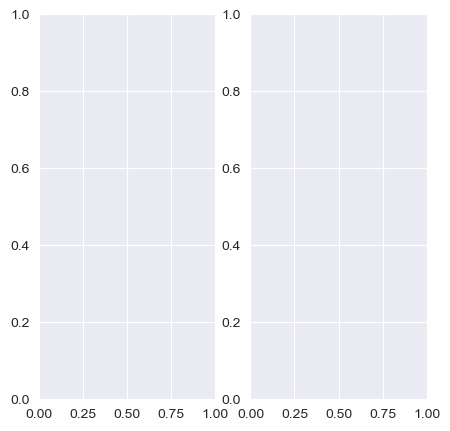

In [19]:
# na = not aligned
l_values_na = sorted(set(key[0] for key in NTK_na))
s_values_na = sorted(set(key[1] for key in NTK_na))

steps_of_interest =[-1]
kernel_heatmaps_na = {step: pd.DataFrame(np.nan, index=l_values_na, columns=s_values_na ) for step in steps_of_interest}

# Populate the heatmaps
for step in steps_of_interest:
    for (param1, param2), distances in NTK_na.items():
        if step <= len(distances):  # Ensure the step exists in the data
            kernel_heatmaps_na[step].loc[param1, param2] =   kernel_distance(distances[0, :, :],distances[step, :, :] ) # Adjust for 0-based indexing
            #kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
    
# Use the scale of the last kernel heatmap and the first loss heatmap
kernel_scale_na = kernel_heatmaps_na[steps_of_interest[-1]]  # Last kernel heatmap

vmin_kernel_na = kernel_scale_na.min().min()
vmax_kernel_na = kernel_scale_na.max().max()

# a = aligned
l_values_a = sorted(set(key[0] for key in NTK_a))
s_values_a = sorted(set(key[1] for key in NTK_a))

kernel_heatmaps_a = {step: pd.DataFrame(np.nan, index=l_values_a, columns=s_values_a ) for step in steps_of_interest}

# Populate the heatmaps
for step in steps_of_interest:
    for (param1, param2), distances in NTK_a.items():
        if step <= len(distances):  # Ensure the step exists in the data
            kernel_heatmaps_a[step].loc[param1, param2] =   kernel_distance(distances[0, :, :],distances[step, :, :] )# Adjust for 0-based indexing
            #kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
    
# Use the scale of the last kernel heatmap and the first loss heatmap
kernel_scale_a = kernel_heatmaps_a[steps_of_interest[-1]]  # Last kernel heatmap

vmin_kernel_a = kernel_scale_a.min().min()
vmax_kernel_a = kernel_scale_a.max().max()


fig, axes = plt.subplots(1, 2, figsize=(5, 5))  # Taller figure for better proportions

# Shared color maps for kernel distance and loss
cmap_kernel_na = 'coolwarm'
cmap_kernel_a = 'coolwarm'

# Plot kernel distance and loss heatmaps for each step

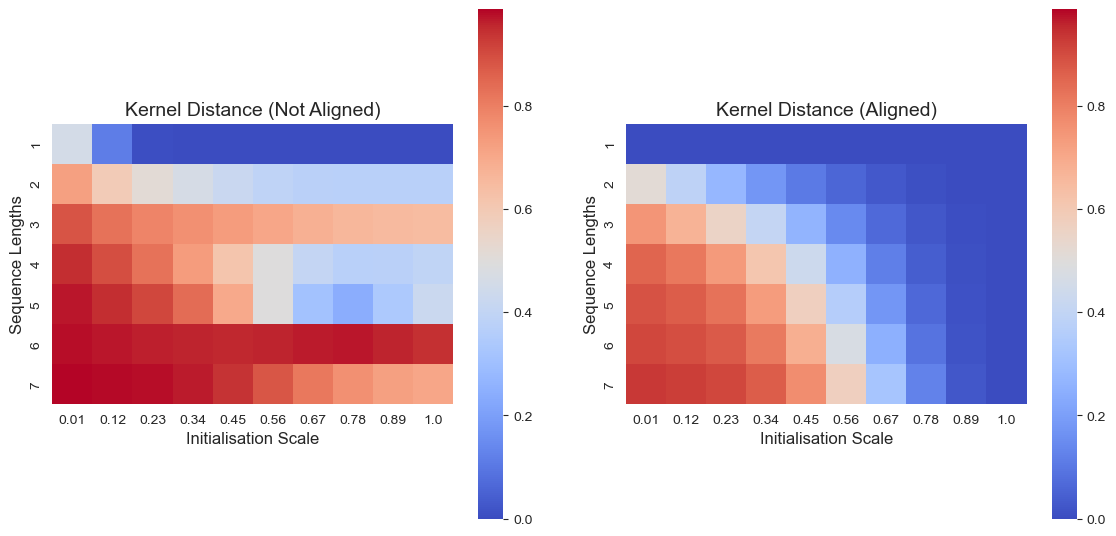

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusted figure size for better readability
fig, axes = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={'width_ratios': [1, 1]})

# Shared color range for both heatmaps
vmin = min(vmin_kernel_na, vmin_kernel_a)
vmax = max(vmax_kernel_na, vmax_kernel_a)

# Plot heatmap for not aligned (na)
sns.heatmap(kernel_heatmaps_na[step],
            ax=axes[0],
            xticklabels=True,
            yticklabels=True,
            cmap='coolwarm',  # Retain the original color map
            cbar=True,
            vmin=vmin, vmax=vmax,
            square=True)
axes[0].set_title('Kernel Distance (Not Aligned)', fontsize=14)
axes[0].set_xlabel('Initialisation Scale', fontsize=12)
axes[0].set_ylabel('Sequence Lengths', fontsize=12)
axes[0].tick_params(axis='both', which='major', labelsize=10)

# Plot heatmap for aligned (a)
sns.heatmap(kernel_heatmaps_a[step],
            ax=axes[1],
            xticklabels=True,
            yticklabels=True,
            cmap='coolwarm',  # Retain the original color map
            cbar=True,
            vmin=vmin, vmax=vmax,
            square=True)
axes[1].set_title('Kernel Distance (Aligned)', fontsize=14)
axes[1].set_xlabel('Initialisation Scale', fontsize=12)
axes[1].set_ylabel('Sequence Lengths', fontsize=12)
axes[1].tick_params(axis='both', which='major', labelsize=10)

# Adjust layout to improve spacing
plt.tight_layout(pad=3)
plt.show()


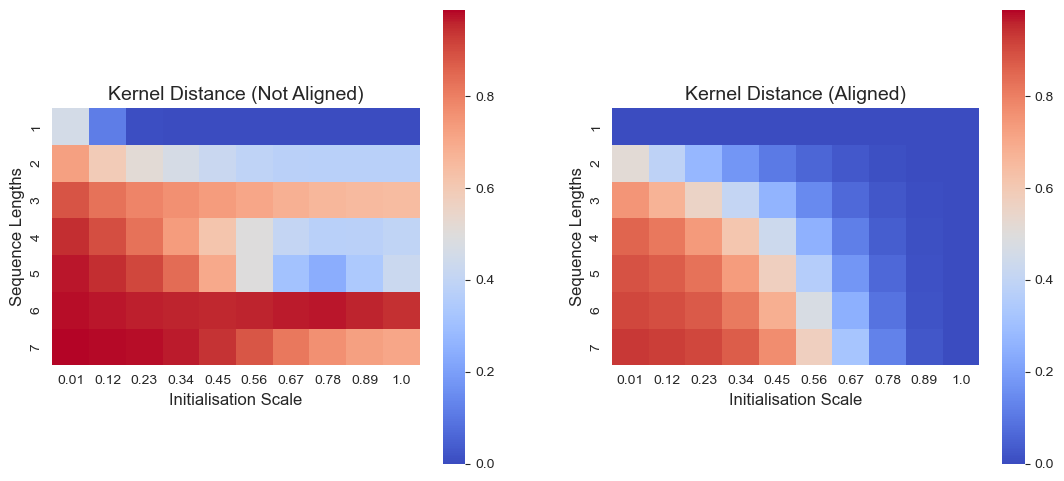

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusted figure size for better readability
fig, axes = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={'width_ratios': [1, 1]})

# Shared color range for both heatmaps
vmin = min(vmin_kernel_na, vmin_kernel_a)
vmax = max(vmax_kernel_na, vmax_kernel_a)

# Plot heatmap for not aligned (na)
sns.heatmap(kernel_heatmaps_na[step],
            ax=axes[0],
            xticklabels=True,  # Show x-axis tick labels
            yticklabels=True,  # Show y-axis tick labels
            cmap='coolwarm',  # Retain the original color map
            cbar=True,  # Show color bar
            vmin=vmin, vmax=vmax,  # Apply consistent color scale
            square=True)
axes[0].set_title('Kernel Distance (Not Aligned)', fontsize=14)
axes[0].set_xlabel('Initialisation Scale', fontsize=12)
axes[0].set_ylabel('Sequence Lengths', fontsize=12)
axes[0].tick_params(axis='both', which='major', labelsize=10)

# Plot heatmap for aligned (a)
sns.heatmap(kernel_heatmaps_a[step],
            ax=axes[1],
            xticklabels=True,  # Show x-axis tick labels
            yticklabels=True,  # Show y-axis tick labels
            cmap='coolwarm',  # Retain the original color map
            cbar=True,  # Show color bar
            vmin=vmin, vmax=vmax,  # Apply consistent color scale
            square=True)
axes[1].set_title('Kernel Distance (Aligned)', fontsize=14)
axes[1].set_xlabel('Initialisation Scale', fontsize=12)
axes[1].set_ylabel('Sequence Lengths', fontsize=12)
axes[1].tick_params(axis='both', which='major', labelsize=10)

# Adjust layout to improve spacing between subplots
plt.tight_layout(pad=5)
plt.show()


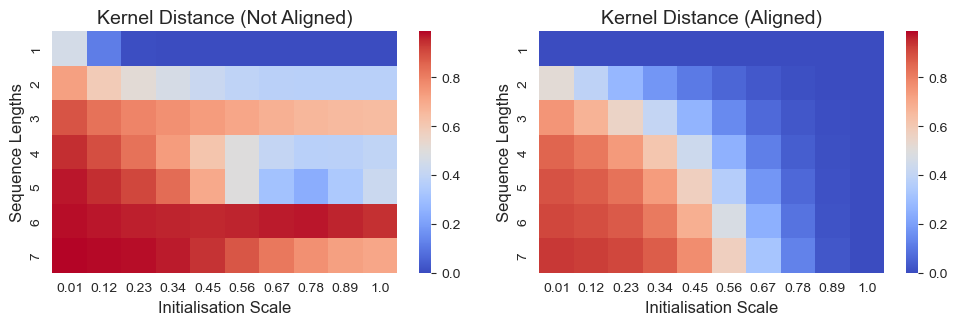

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusted figure size to make it more compact
fig, axes = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 1]})

# Shared color range for both heatmaps
vmin = min(vmin_kernel_na, vmin_kernel_a)
vmax = max(vmax_kernel_na, vmax_kernel_a)

# Plot heatmap for not aligned (na)
sns.heatmap(kernel_heatmaps_na[step],
            ax=axes[0],
            xticklabels=True,  # Show x-axis tick labels
            yticklabels=True,  # Show y-axis tick labels
            cmap='coolwarm',  # Retain the original color map
            cbar=True,  # Show color bar
            vmin=vmin, vmax=vmax,  # Apply consistent color scale
            square=True)
axes[0].set_title('Kernel Distance (Not Aligned)', fontsize=14)
axes[0].set_xlabel('Initialisation Scale', fontsize=12)
axes[0].set_ylabel('Sequence Lengths', fontsize=12)
axes[0].tick_params(axis='both', which='major', labelsize=10)

# Plot heatmap for aligned (a)
sns.heatmap(kernel_heatmaps_a[step],
            ax=axes[1],
            xticklabels=True,  # Show x-axis tick labels
            yticklabels=True,  # Show y-axis tick labels
            cmap='coolwarm',  # Retain the original color map
            cbar=True,  # Show color bar
            vmin=vmin, vmax=vmax,  # Apply consistent color scale
            square=True)
axes[1].set_title('Kernel Distance (Aligned)', fontsize=14)
axes[1].set_xlabel('Initialisation Scale', fontsize=12)
axes[1].set_ylabel('Sequence Lengths', fontsize=12)
axes[1].tick_params(axis='both', which='major', labelsize=10)

# Adjust layout for better spacing and compactness
plt.tight_layout(pad=1)  # Reduce padding between subplots
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusted figure size & grid specifications
fig, axes = plt.subplots(1, 4, figsize=(12, 10), 
                         gridspec_kw={'width_ratios': [1, 1, 1, 0.05]})  # Last subplot for colorbar

# Shared color range for all heatmaps
vmin = min(vmin_kernel_1, vmin_kernel_2, vmin_kernel_3)
vmax = max(vmax_kernel_1, vmax_kernel_2, vmax_kernel_3)

# Create heatmaps without individual colorbars
heatmaps = []
for i, kernel in enumerate([kernel_heatmaps_1, kernel_heatmaps_2, kernel_heatmaps_3]):
    heatmaps.append(
        sns.heatmap(kernel[step],
                    ax=axes[i],
                    xticklabels=True,
                    yticklabels=True,
                    cmap='coolwarm',
                    cbar=False,  # Disable individual colorbars
                    vmin=vmin, vmax=vmax,
                    square=True)
    )
    axes[i].set_title(f'Kernel Distance {i+1}', fontsize=14)
    axes[i].set_xlabel('Init Scale Recurrent Modes', fontsize=12)
    axes[i].set_ylabel('Init Scale Input Output Mode', fontsize=12)
    axes[i].tick_params(axis='both', which='major', labelsize=10)

# Add a **shared colorbar** in the last subplot
cbar_ax = axes[3]  # Use the last axis slot for the colorbar
fig.colorbar(heatmaps[0].collections[0], cax=cbar_ax)  # Use first heatmap's colorbar

# Improve layout
plt.tight_layout()
plt.show()
